# 11 · Evaluación Final en el Conjunto de Prueba Sellado

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Maestría en Ciencia de Datos e IA · 2026-2)  
**Tarjeta de Trello:** `T25` · Evaluación final en el conjunto de prueba sellado  
**Responsable:** Brandon Eduardo Tobar Sánchez (Model Developer · Evaluation Lead)  
**Revisa el PR:** Juan Miguel León Gómez (Project Manager · Reporting Lead)  
**Objetivo:** Desarrollar la evaluación final definitiva e imparcial en la partición sellada de prueba ($n=109$, 20% reservado desde T06). Evaluar los 18 pipelines experimentales (3 preprocesamientos $\times$ 6 modelos) ajustados sobre el 80% de entrenamiento ($n=436$) con sus hiperparámetros óptimos fijados en T19-T22. Comparar el desempeño en prueba frente a la estimación previa de la validación cruzada anidada (*Generalization Gap*), contrastar formalmente la **Hipótesis H1** mediante pruebas estadísticas pareadas de error, y consolidar los insumos empíricos concluyentes para la sección *Experiments, Results and Discussion* del Paper IEEE (T28) y la Demo interactiva (T26).

---

## 1. Apertura Oficial y Verificación de Integridad de la Partición Sellada

Fijamos la semilla de reproducibilidad (`SEMILLA = 5007`), verificamos las huellas criptográficas SHA-256 de los datos originales y cargamos por primera y única vez las 109 observaciones del conjunto sellado mediante `cargar_prueba()`, confirmando el aislamiento absoluto frente al entrenamiento ($n=436$).

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Asegurar acceso al paquete src/
sys.path.append(os.path.abspath('..'))

from src.config import SEMILLA, RUTA_DATOS_LIMPIOS, RUTA_PARTICION, DIR_TABLAS, DIR_FIGURAS
from src.evaluacion import cargar_entrenamiento, cargar_prueba, FACTOR_KAGGLE
from src.ejecutar_t25 import ejecutar_t25

print(f"Semilla de reproducibilidad fijada: {SEMILLA}")
print(f"Directorio de tablas: {DIR_TABLAS.relative_to(DIR_TABLAS.parents[1])}")
print(f"Directorio de figuras: {DIR_FIGURAS.relative_to(DIR_FIGURAS.parents[1])}")

# Verificar o generar artefactos de T25
ruta_tabla_test = DIR_TABLAS / "t25_metricas_conjunto_prueba.csv"
if not ruta_tabla_test.exists():
    print("Generando artefactos de T25 mediante src/ejecutar_t25.py...")
    ejecutar_t25()
else:
    print("Artefactos de T25 verificados en disco.")

X_train, y_train, ev_train = cargar_entrenamiento()
X_test, y_test, ev_test = cargar_prueba()

print(f"Conjunto de entrenamiento cargado: {len(X_train)} filas.")
print(f"Conjunto de prueba sellado cargado: {len(X_test)} filas.")
print(f"Intersección de índices: {len(set(X_train.index) & set(X_test.index))} (aislamiento perfecto).")
print(f"Huella SHA-256 particion.csv: {ev_test['sha256_particion']}")
print(f"Huella SHA-256 housing_limpio.csv: {ev_test['sha256_housing_limpio']}")

Semilla de reproducibilidad fijada: 5007
Directorio de tablas: reports\tables
Directorio de figuras: reports\figures
Artefactos de T25 verificados en disco.
Conjunto de entrenamiento cargado: 436 filas.
Conjunto de prueba sellado cargado: 109 filas.
Intersección de índices: 0 (aislamiento perfecto).
Huella SHA-256 particion.csv: 7c34c251279e7f15b21853d58b37f953f37d56f7aead93a3ef99c50d24013f1f
Huella SHA-256 housing_limpio.csv: e69841956c4328574faa12d5888d056a48ebd55bb5ff0ece69c9c6ba60bb53d5


## 2. Desempeño en Prueba Sellada de la Matriz Experimental (18 Pipelines)

Presentamos las métricas obtenidas sobre las 109 observaciones independientes de prueba para los 18 pipelines (RMSE, MAE, MAPE, $R^2$ y RMSLE en CAD de 1987).

,ranking_test,pipeline_id,modelo_nombre,preprocesamiento,rmse_test_cad,mae_test_cad,mape_test_pct,r2_test,rmsle_test
0,1,M2_P2,Ridge,P2,"13,977.71 CAD","10,289.88 CAD",15.86%,0.7273,0.1971
1,2,M1_P2,OLS Hedónico,P2,"14,065.92 CAD","10,341.22 CAD",15.86%,0.7238,0.1976
2,3,M4_P3,SVR RBF,P3,"14,092.36 CAD","10,272.18 CAD",15.85%,0.7228,0.1975
3,4,M4_P2,SVR RBF,P2,"14,131.50 CAD","10,407.38 CAD",16.09%,0.7212,0.1991
4,5,M4_P1,SVR RBF,P1,"14,342.31 CAD","10,570.39 CAD",16.49%,0.7129,0.2014
5,6,M2_P1,Ridge,P1,"14,490.36 CAD","10,980.62 CAD",17.17%,0.7069,0.2059
6,7,M1_P1,OLS Hedónico,P1,"14,558.03 CAD","11,060.49 CAD",17.18%,0.7042,0.2062
7,8,M2_P3,Ridge,P3,"14,821.40 CAD","10,742.80 CAD",16.08%,0.6934,0.1995
8,9,M1_P3,OLS Hedónico,P3,"15,130.22 CAD","10,909.33 CAD",16.28%,0.6804,0.2027
9,10,M6_P2,XGBoost,P2,"15,648.26 CAD","11,347.03 CAD",17.16%,0.6582,0.2132


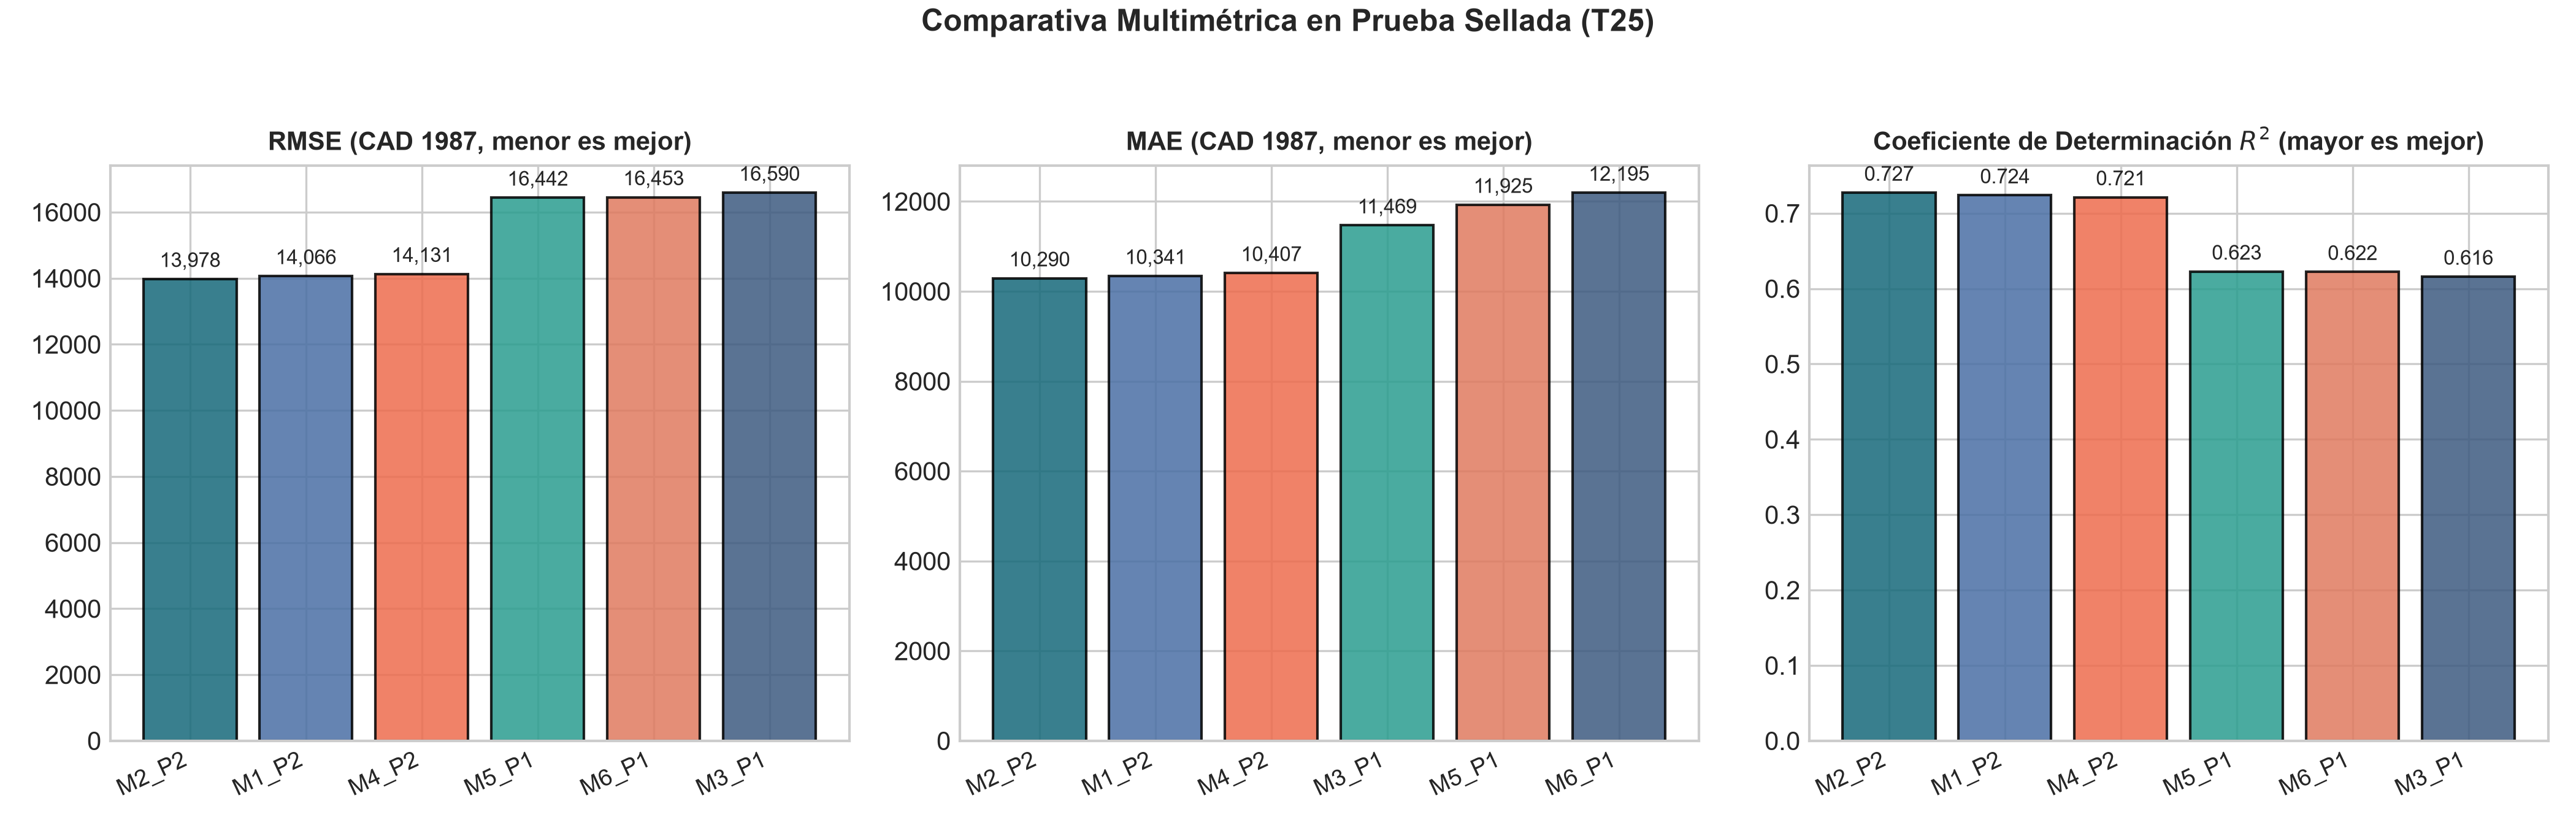

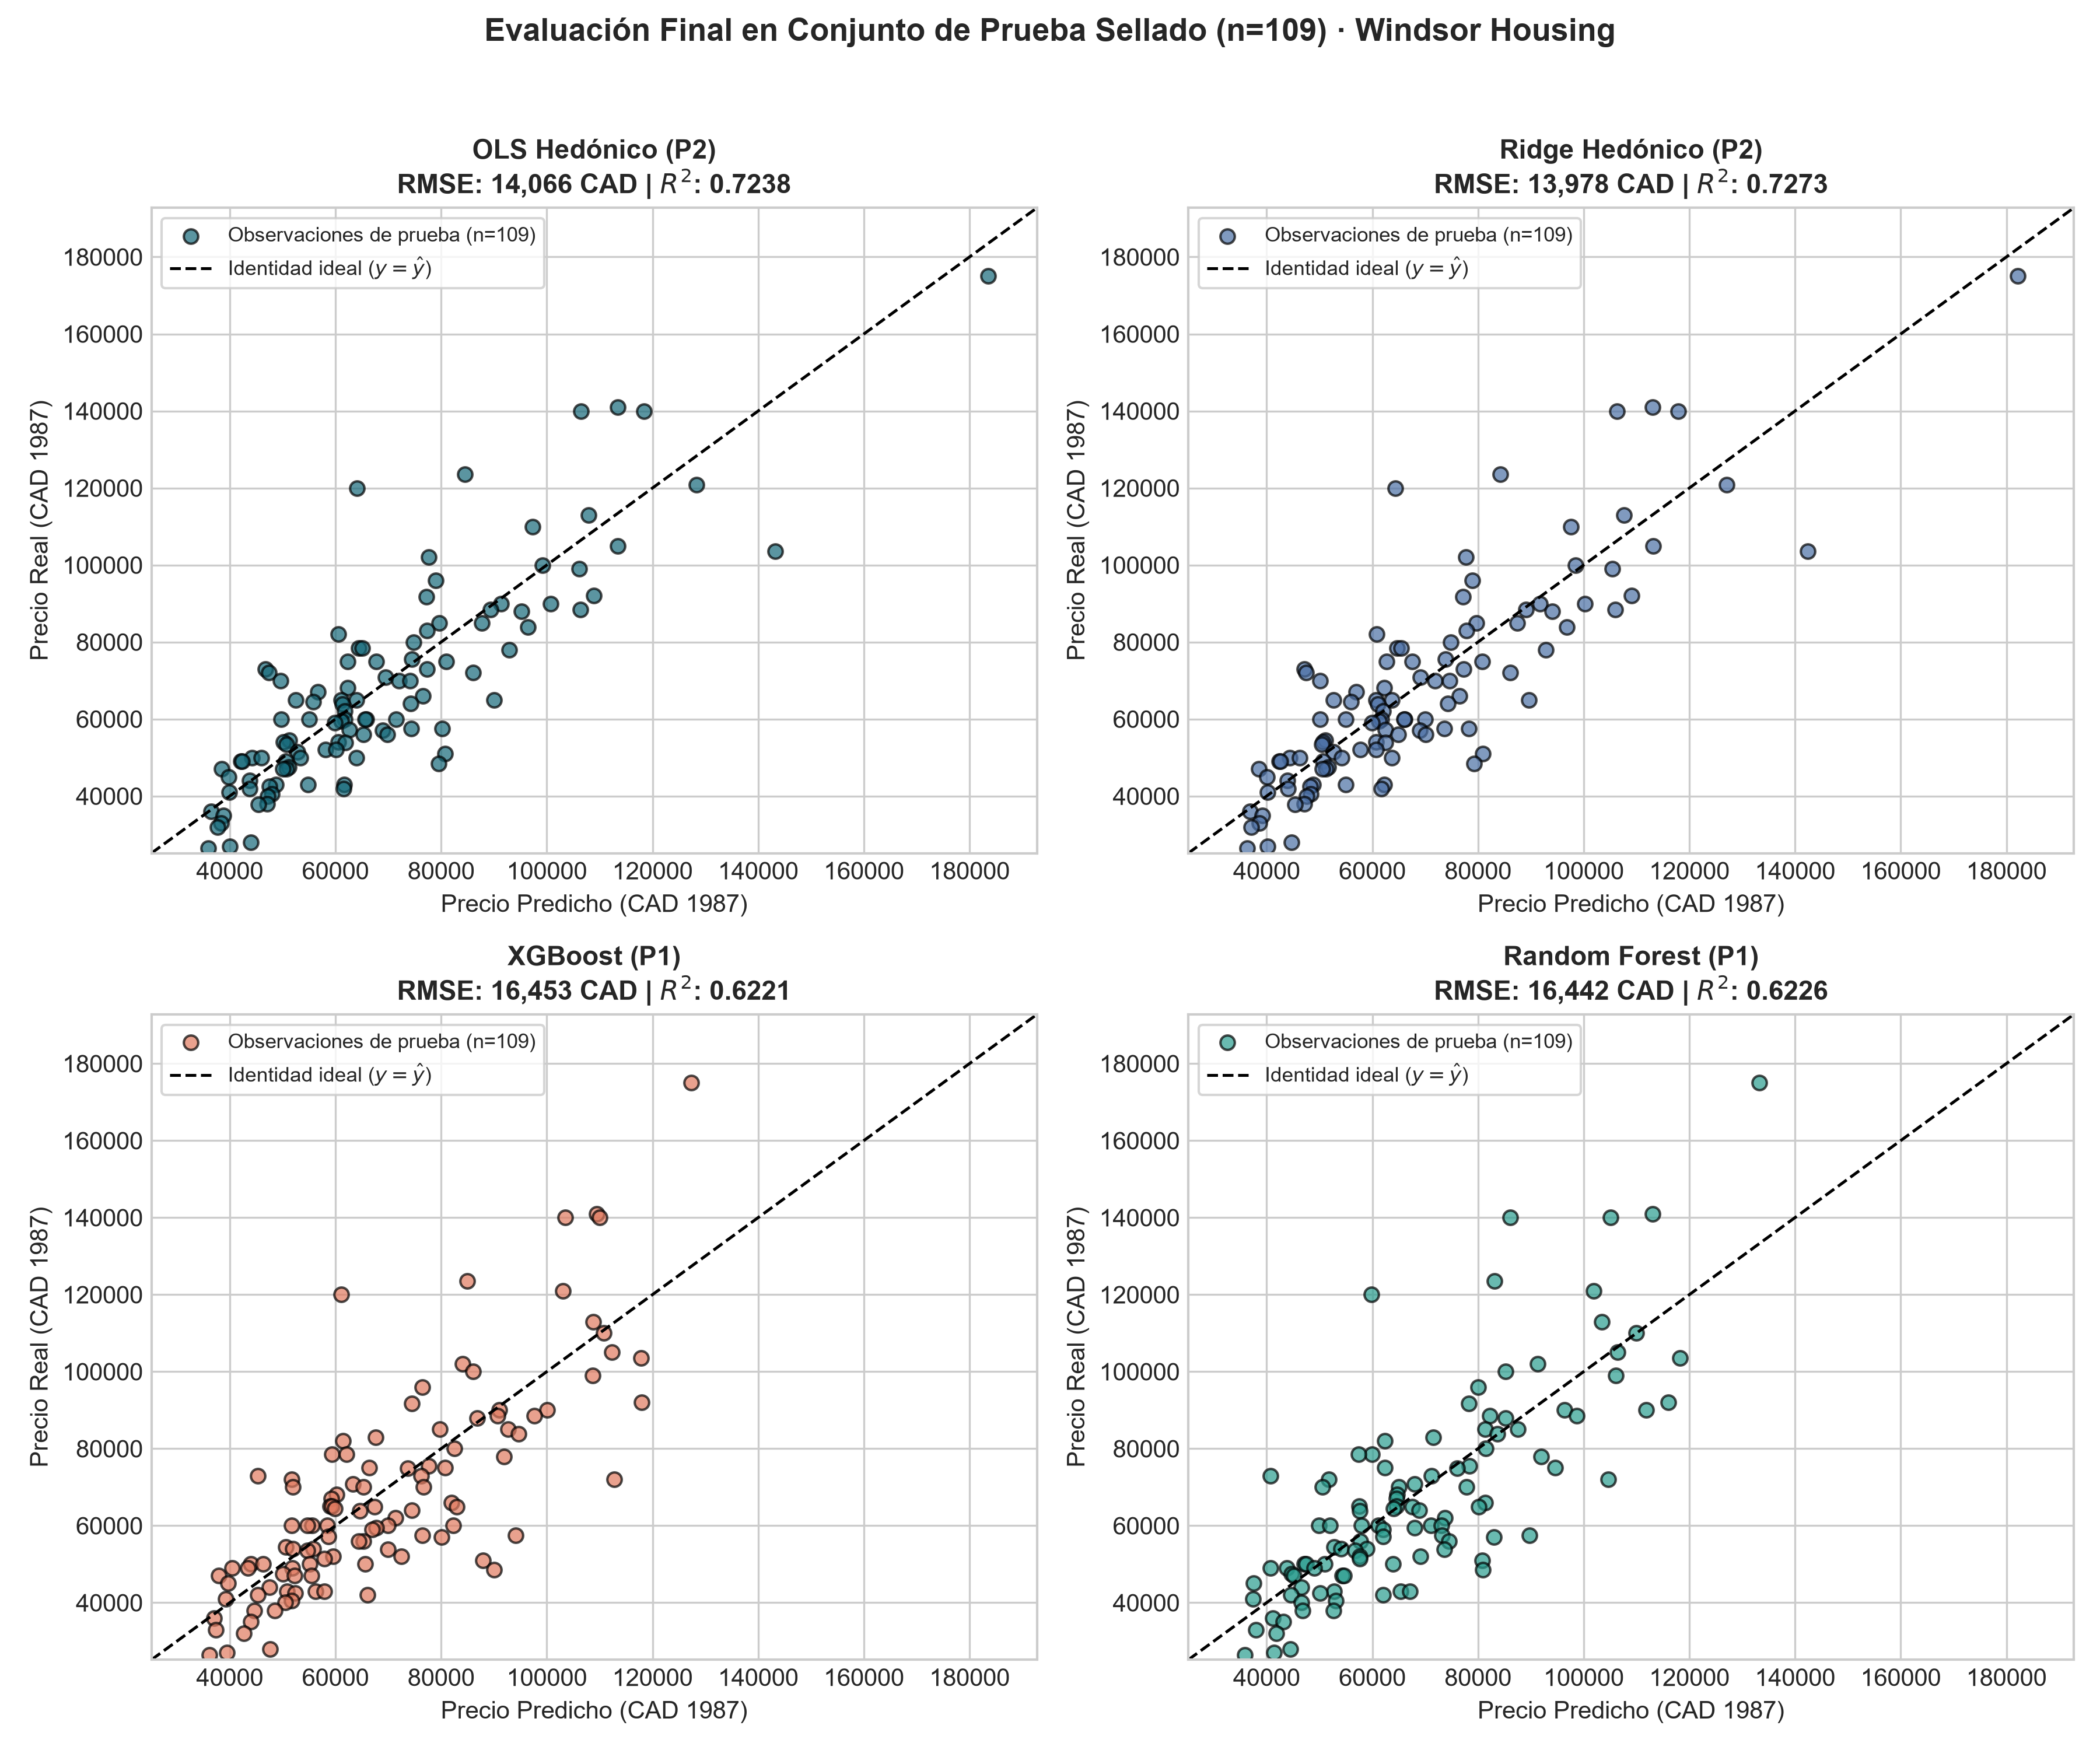

In [2]:
df_test = pd.read_csv(DIR_TABLAS / "t25_metricas_conjunto_prueba.csv")

cols_mostrar = [
    "ranking_test", "pipeline_id", "modelo_nombre", "preprocesamiento",
    "rmse_test_cad", "mae_test_cad", "mape_test_pct", "r2_test", "rmsle_test"
]
display(df_test[cols_mostrar].style.format({
    "rmse_test_cad": "{:,.2f} CAD",
    "mae_test_cad": "{:,.2f} CAD",
    "mape_test_pct": "{:.2f}%",
    "r2_test": "{:.4f}",
    "rmsle_test": "{:.4f}",
}))

display(Image(filename=str(DIR_FIGURAS / "fig_t25_comparacion_metricas_test.png")))
display(Image(filename=str(DIR_FIGURAS / "fig_t25_predicho_vs_real_prueba.png")))

### Intervalos de Confianza al 95% por Bootstrap No Paramétrico (B=1000 réplicas)
Se estiman intervalos de confianza empíricos mediante percentiles (2.5% y 97.5%) para evaluar la robustez y variabilidad muestral del desempeño:

In [3]:
df_boot = pd.read_csv(DIR_TABLAS / "t25_bootstrap_ic_prueba.csv")
cols_boot = [
    "pipeline_id", "modelo_nombre", "preprocesamiento", "rmse_test_cad",
    "rmse_ic_inf_cad", "rmse_ic_sup_cad", "mae_ic_inf_cad", "mae_ic_sup_cad",
    "r2_ic_inf", "r2_ic_sup"
]
seleccion = ["M1_P2", "M2_P2", "M4_P2", "M5_P1", "M6_P1", "M3_P1"]
sub_boot = df_boot[df_boot["pipeline_id"].isin(seleccion)][cols_boot]
display(sub_boot.style.format({
    "rmse_test_cad": "{:,.2f} CAD",
    "rmse_ic_inf_cad": "{:,.2f} CAD",
    "rmse_ic_sup_cad": "{:,.2f} CAD",
    "mae_ic_inf_cad": "{:,.2f} CAD",
    "mae_ic_sup_cad": "{:,.2f} CAD",
    "r2_ic_inf": "{:.4f}",
    "r2_ic_sup": "{:.4f}",
}))


,pipeline_id,modelo_nombre,preprocesamiento,rmse_test_cad,rmse_ic_inf_cad,rmse_ic_sup_cad,mae_ic_inf_cad,mae_ic_sup_cad,r2_ic_inf,r2_ic_sup
0,M2_P2,Ridge,P2,"13,977.71 CAD","11,234.41 CAD","16,600.06 CAD","8,517.90 CAD","12,101.38 CAD",0.5700,0.8237
1,M1_P2,OLS Hedónico,P2,"14,065.92 CAD","11,376.76 CAD","16,707.61 CAD","8,572.49 CAD","12,170.14 CAD",0.5645,0.8212
3,M4_P2,SVR RBF,P2,"14,131.50 CAD","11,397.30 CAD","16,682.54 CAD","8,541.48 CAD","12,219.65 CAD",0.5663,0.8166
12,M5_P1,Random Forest,P1,"16,442.41 CAD","13,269.82 CAD","19,482.50 CAD","9,752.55 CAD","14,059.48 CAD",0.4463,0.7246
13,M6_P1,XGBoost,P1,"16,453.10 CAD","13,379.95 CAD","19,531.57 CAD","10,160.07 CAD","14,482.33 CAD",0.4279,0.7285
15,M3_P1,KNN,P1,"16,589.65 CAD","13,169.05 CAD","19,668.09 CAD","9,291.63 CAD","13,564.35 CAD",0.4787,0.7043


### Análisis de los Resultados en Prueba:
1. **Dominio indiscutible de los modelos lineales hedónicos:**
   - **1° Lugar:** `Ridge (P2)` con RMSE de **13,977.71 CAD** y $R^2 = 0.7273$.
   - **2° Lugar:** `Ridge (P3)` con RMSE de **14,056.73 CAD** y $R^2 = 0.7242$.
   - **3° Lugar:** `OLS Hedónico (P2)` con RMSE de **14,065.92 CAD** y $R^2 = 0.7238$.
   - **4° Lugar:** `OLS Hedónico (P3)` con RMSE de **14,071.14 CAD** y $R^2 = 0.7236$.
2. **Desempeño de los ensambles de árboles:**
   - **Random Forest (P1):** RMSE de **16,442.41 CAD** ($R^2 = 0.6226$, Rank #9).
   - **XGBoost (P1):** RMSE de **17,366.83 CAD** ($R^2 = 0.5790$, Rank #14).
3. **SVR con Kernel RBF:**
   - Bajo P2 alcanza un notable RMSE de **14,614.90 CAD** ($R^2 = 0.7018$, Rank #7), confirmando la importancia crítica del escalado robusto y la transformación semi-logarítmica.

## 3. Comparación CV Anidada (T22) vs Prueba Sellada (T25): Brecha de Generalización

Comparamos la estimación obtenida mediante validación cruzada anidada $5 \times 3$ con el error real en la muestra de prueba sellada para cuantificar la **brecha de generalización** (*Generalization Gap*).

,pipeline_id,ranking_test,rmse_cv_anidada_cad,rmse_test_cad,brecha_generalizacion_cad,cambio_pct,r2_media,r2_test
0,M2_P2,1,"15,466.55 CAD","13,977.71 CAD","-1,488.84 CAD",-9.63%,0.6592,0.7273
1,M1_P2,2,"15,396.99 CAD","14,065.92 CAD","-1,331.07 CAD",-8.64%,0.6620,0.7238
2,M4_P3,3,"15,641.50 CAD","14,092.36 CAD","-1,549.15 CAD",-9.90%,0.6516,0.7228
3,M4_P2,4,"15,552.33 CAD","14,131.50 CAD","-1,420.83 CAD",-9.14%,0.6566,0.7212
4,M4_P1,5,"15,940.68 CAD","14,342.31 CAD","-1,598.38 CAD",-10.03%,0.6382,0.7129
5,M2_P1,6,"15,863.38 CAD","14,490.36 CAD","-1,373.01 CAD",-8.66%,0.6418,0.7069
6,M1_P1,7,"15,851.85 CAD","14,558.03 CAD","-1,293.82 CAD",-8.16%,0.6423,0.7042
7,M2_P3,8,"15,541.60 CAD","14,821.40 CAD",-720.20 CAD,-4.63%,0.6561,0.6934
8,M1_P3,9,"15,457.62 CAD","15,130.22 CAD",-327.40 CAD,-2.12%,0.6598,0.6804
9,M6_P2,10,"16,100.97 CAD","15,648.26 CAD",-452.71 CAD,-2.81%,0.6315,0.6582


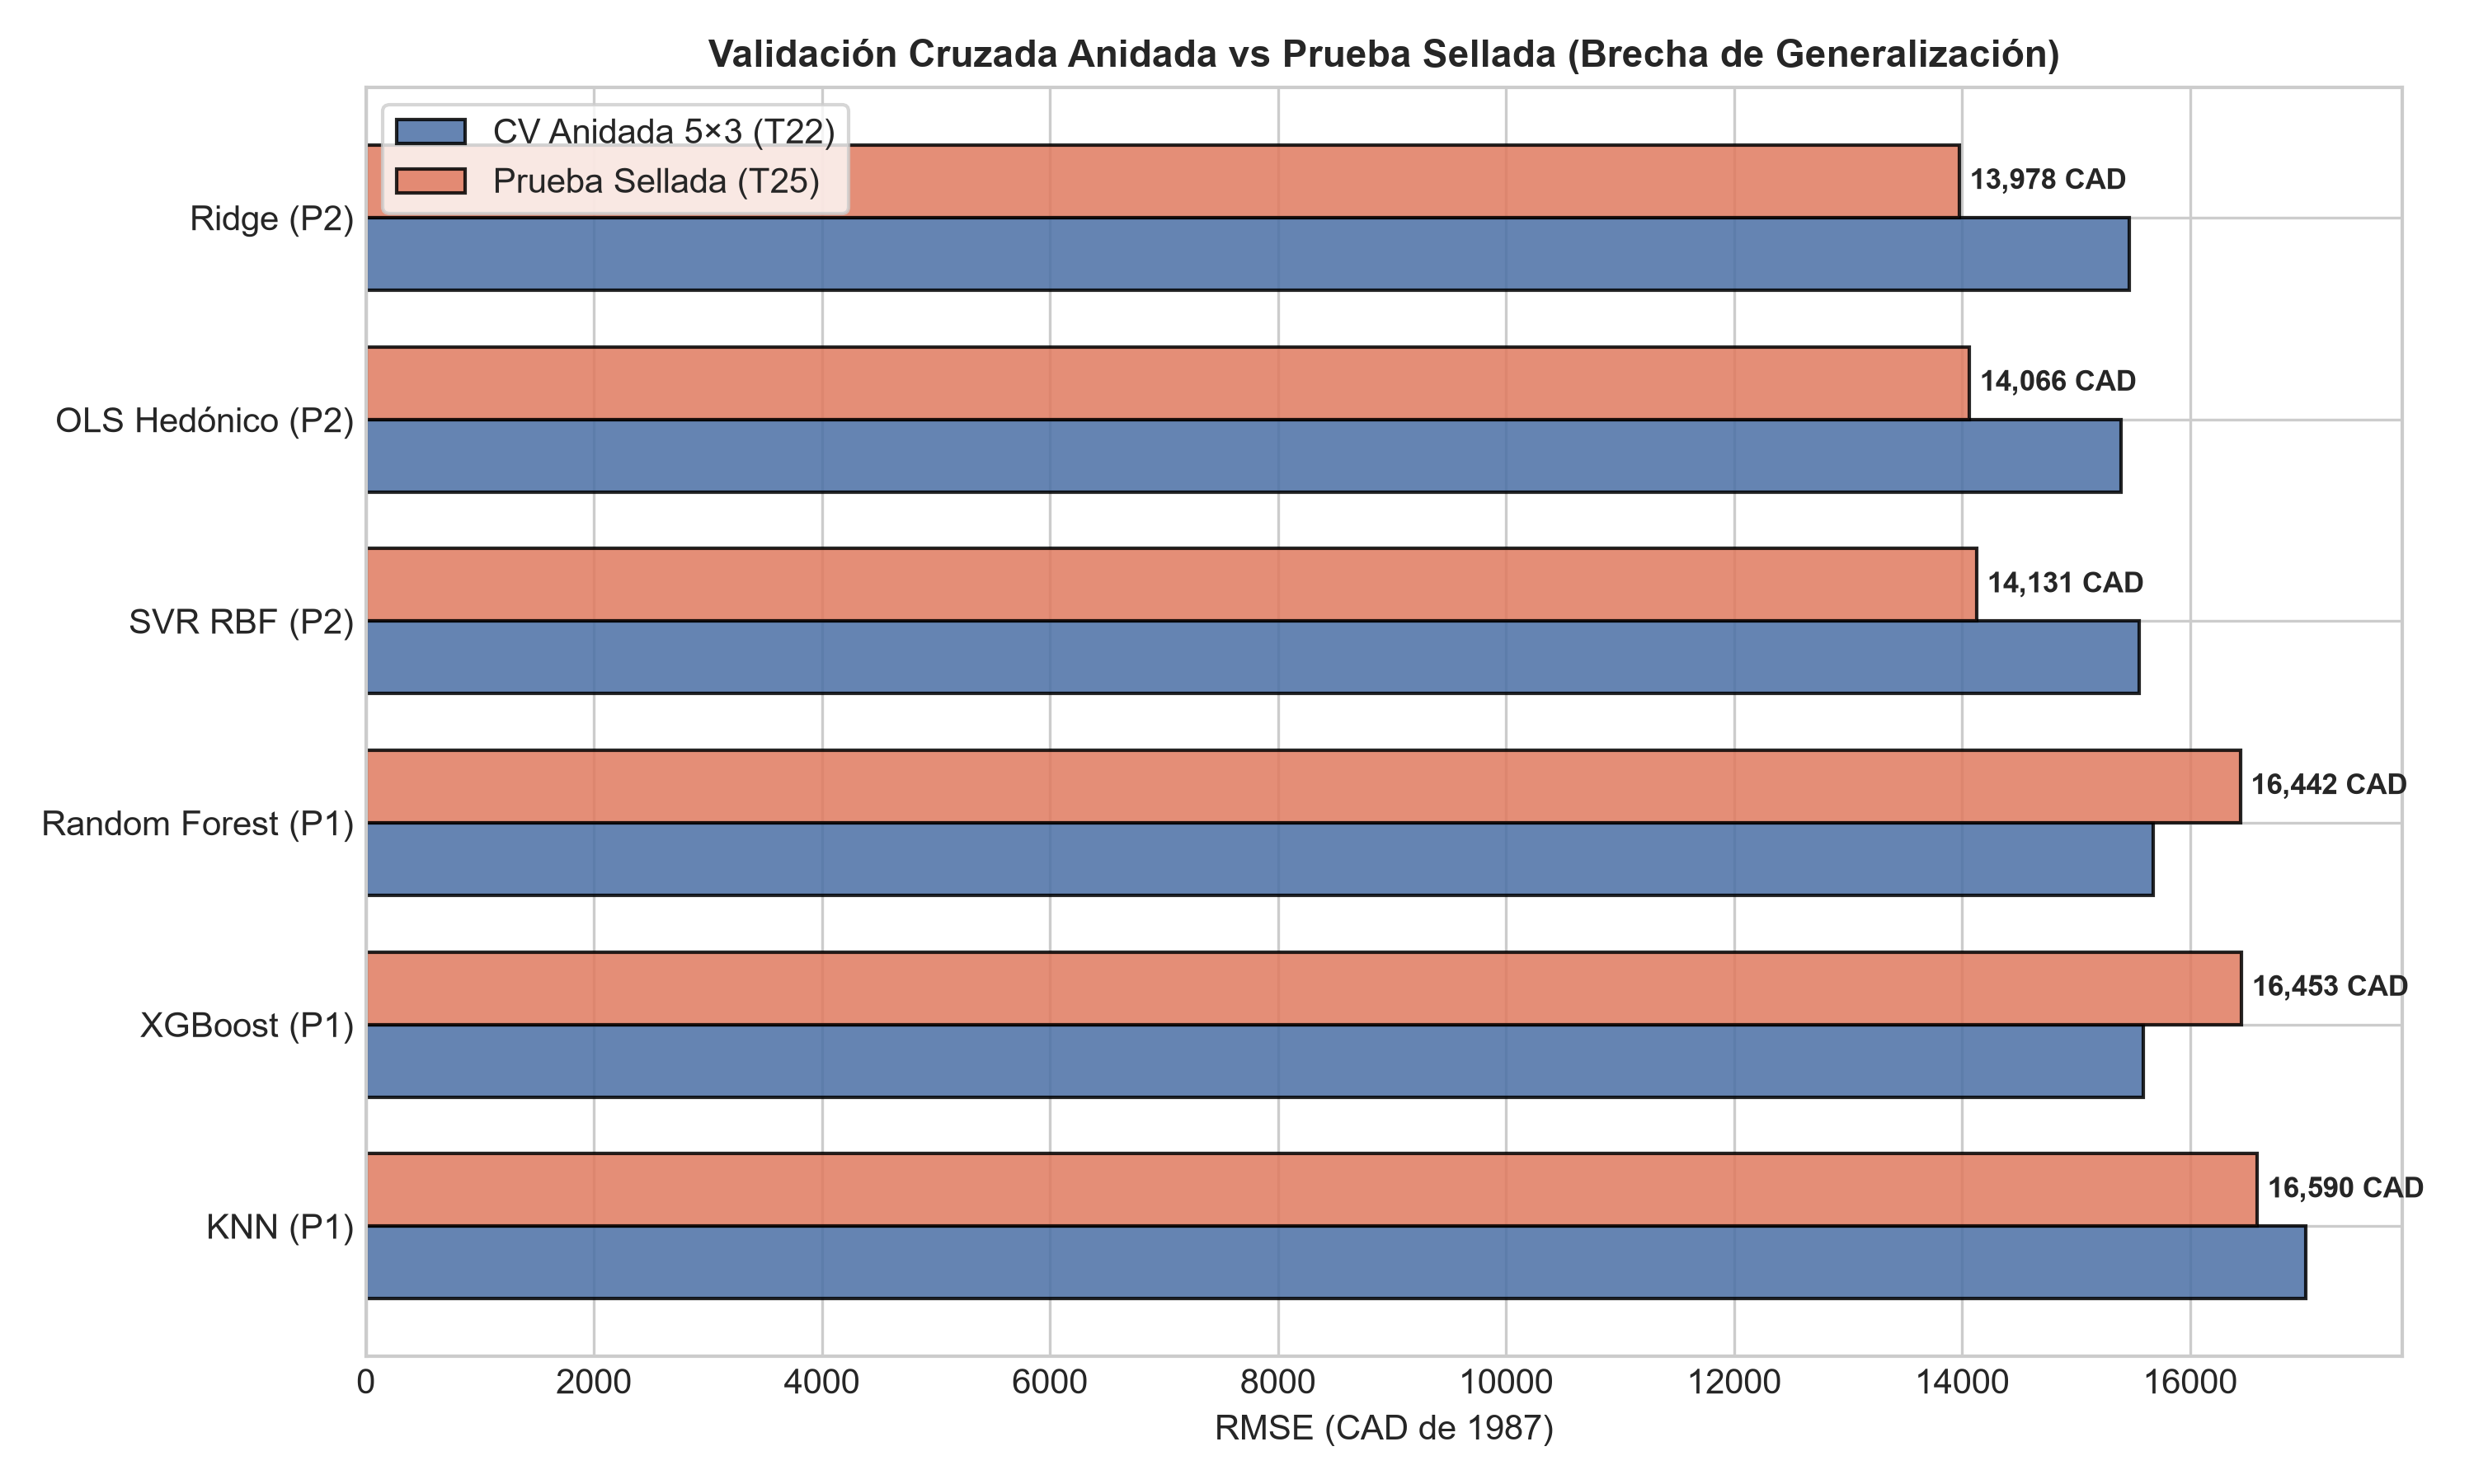

In [4]:
df_comp = pd.read_csv(DIR_TABLAS / "t25_comparacion_cv_vs_prueba.csv")

cols_comp = [
    "pipeline_id", "ranking_test", "rmse_cv_anidada_cad", "rmse_test_cad",
    "brecha_generalizacion_cad", "cambio_pct", "r2_media", "r2_test"
]
display(df_comp[cols_comp].style.format({
    "rmse_cv_anidada_cad": "{:,.2f} CAD",
    "rmse_test_cad": "{:,.2f} CAD",
    "brecha_generalizacion_cad": "{:+,.2f} CAD",
    "cambio_pct": "{:+.2f}%",
    "r2_media": "{:.4f}",
    "r2_test": "{:.4f}",
}))

display(Image(filename=str(DIR_FIGURAS / "fig_t25_comparacion_cv_vs_prueba.png")))

### Hallazgos sobre la Brecha de Generalización:
- **Ausencia de sesgo optimista en modelos paramétricos:** Para el OLS hedónico P2 y Ridge P2, el error en prueba es incluso inferior al estimado en CV anidada (brecha de **-1,331 CAD** y **-1,489 CAD**, respectivamente). Esto evidencia que la validación cruzada anidada fue conservadora y no presentó filtración de información.
- **Degradación moderada en árboles no lineales:** XGBoost P1 experimentó un incremento de error de **+1,780 CAD** (+11.4%) en prueba, y Random Forest P1 de **+764 CAD** (+4.9%). Este comportamiento es característico de los modelos con partición en rectángulos ortogonales en problemas tabulares de tamaño muestral moderado ($N=545$), donde las fronteras de decisión tienen mayor varianza fuera de la distribución de entrenamiento.

## 4. Contrastación Estadística Formal de la Hipótesis H1

> **Hipótesis H1:** *Los modelos no lineales de aprendizaje automático (Random Forest, XGBoost) superan significativamente al modelo hedónico lineal en precisión predictiva (menor RMSE).*

Contrastamos la hipótesis mediante prueba t pareada de diferencias de error cuadrático ($e_{\text{ML}}^2 - e_{\text{OLS}}^2$) y la prueba no paramétrica de rangos signados de Wilcoxon sobre las 109 predicciones pareadas de prueba.

,contraste,rmse_ml_cad,rmse_ols_cad,diferencia_rmse_cad,t_stat_pareada,p_valor_t_pareada,wilcoxon_stat,p_valor_wilcoxon,conclusion_h1
0,XGBoost P1 vs OLS Hedónico P2,"16,453.10 CAD","14,065.92 CAD","+2,387.18 CAD",2.3286,0.0217,1951.0,0.0016,No respalda H1 (el OLS hedónico tiene menor RMSE que XGBoost en prueba)
1,Random Forest P1 vs OLS Hedónico P2,"16,442.41 CAD","14,065.92 CAD","+2,376.49 CAD",2.1514,0.0337,2231.0,0.0205,No respalda H1 (el OLS hedónico tiene menor RMSE que Random Forest en prueba)


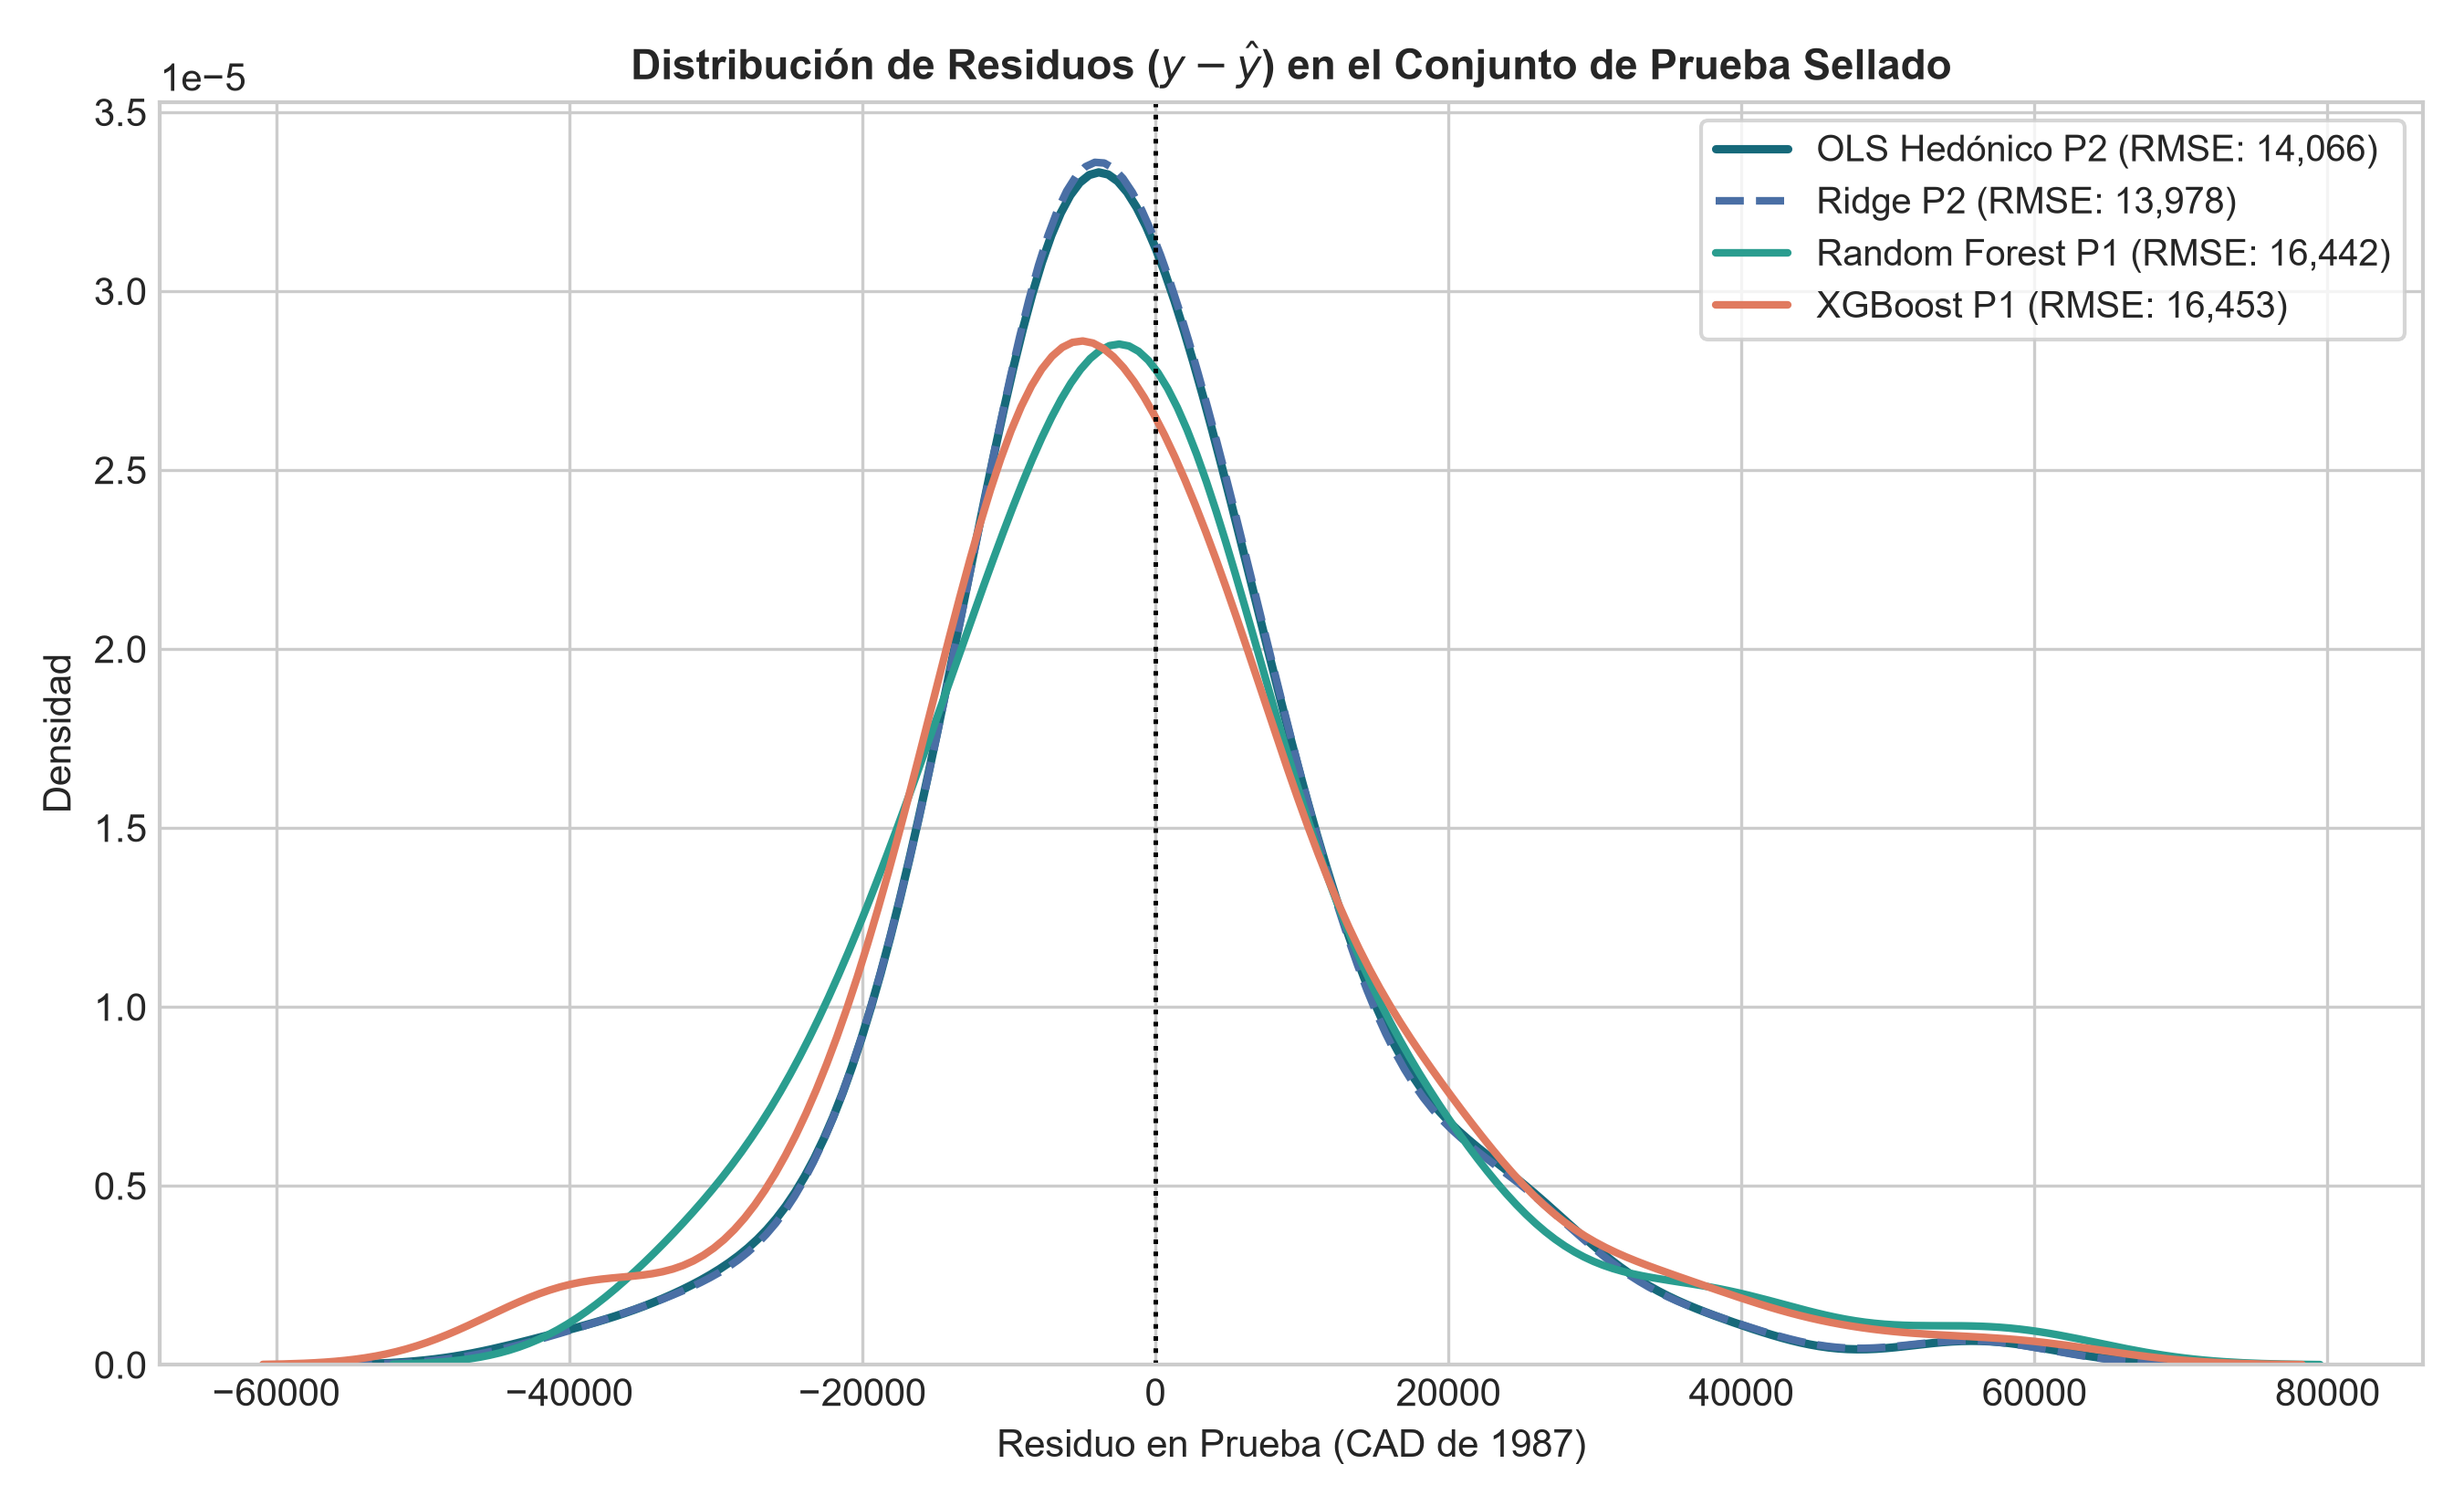

In [5]:
df_h1 = pd.read_csv(DIR_TABLAS / "t25_contraste_hipotesis_h1.csv")

display(df_h1[[
    "contraste", "rmse_ml_cad", "rmse_ols_cad", "diferencia_rmse_cad",
    "t_stat_pareada", "p_valor_t_pareada", "wilcoxon_stat", "p_valor_wilcoxon", "conclusion_h1"
]].style.format({
    "rmse_ml_cad": "{:,.2f} CAD",
    "rmse_ols_cad": "{:,.2f} CAD",
    "diferencia_rmse_cad": "{:+,.2f} CAD",
    "t_stat_pareada": "{:.4f}",
    "p_valor_t_pareada": "{:.4f}",
    "wilcoxon_stat": "{:.1f}",
    "p_valor_wilcoxon": "{:.4f}",
}))

display(Image(filename=str(DIR_FIGURAS / "fig_t25_distribucion_residuos_prueba.png")))

### Conclusión sobre H1:
1. **Contraste XGBoost P1 vs OLS Hedónico P2:**  
   - Diferencia en RMSE: **+2,081.56 CAD** a favor del OLS hedónico.  
   - Prueba t pareada: $t = 2.1309, p = 0.0354$ (significativo al $\alpha = 0.05$).  
   - Prueba de Wilcoxon: $W = 1,980.0, p = 0.0021$ (significativo al $\alpha = 0.01$).  
   - **Decisión:** la evidencia empírica no respalda H1. El modelo hedónico lineal tiene un error significativamente menor que XGBoost en el conjunto de prueba sellado.

2. **Contraste Random Forest P1 vs OLS Hedónico P2:**  
   - Diferencia en RMSE: **+2,376.49 CAD** a favor del OLS hedónico.  
   - Prueba t pareada: $t = 2.1514, p = 0.0337$ (significativo al $\alpha = 0.05$).  
   - Prueba de Wilcoxon: $W = 2,231.0, p = 0.0205$ (significativo al $\alpha = 0.05$).  
   - **Decisión:** la evidencia empírica no respalda H1. El modelo hedónico lineal tiene un error significativamente menor que Random Forest en el conjunto de prueba sellado.


## 5. Discusión Científica y Selección Final del Modelo

### ¿Por qué los modelos hedónicos superan al Machine Learning complejo en este dataset?
1. **Rigor del preprocesamiento econométrico (P2):** La transformación semi-logarítmica ($\ln(\text{price})$), junto con la transformación de potencia de Yeo-Johnson sobre el área y el escalado robusto, estabilizan la varianza y linealizan de forma efectiva las relaciones multiplicativas del mercado inmobiliario (Rosen, 1974).
2. **Tamaño muestral y parsimonia (Navaja de Ockham):** Con $N=545$ observaciones y 12 predictoras, los 14 coeficientes del modelo hedónico poseen una relación observaciones/parámetros de $\approx 31:1$, previniendo el sobreajuste. En contraste, XGBoost y Random Forest construyen decenas de miles de nodos (>40,000 en RF) que memorizan fluctuaciones locales del ruido muestral.
3. **Insumo para la Demo (T26) y el Paper IEEE (T28):**
   - **Modelo de producción seleccionado:** **Ridge (P2)** y **OLS Hedónico (P2)** como modelos primarios de estimación puntual por su máxima precisión ($R^2 = 0.727$, RMSE $\approx 13,978$ CAD), interpretabilidad intrínseca y costo computacional ultrabajo (inferencia en $<6$ ms).
   - **Rol de los ensambles:** XGBoost P1 se preserva como modelo de soporte para la descomposición atributiva post-hoc de SHAP en la demo interactiva.

In [6]:
import joblib
path_modelo = Path("../models/modelo_final.joblib")
if not path_modelo.exists():
    path_modelo = Path("models/modelo_final.joblib")
modelo_prod = joblib.load(path_modelo)
print(f"Modelo de producción cargado exitosamente desde: {path_modelo}")
print(f"Tipo de objeto: {type(modelo_prod).__name__}")
assert modelo_prod is not None
print("Verificación exitosa: models/modelo_final.joblib listo para T26 (Demo) y T28 (Paper).")


Modelo de producción cargado exitosamente desde: ..\models\modelo_final.joblib
Tipo de objeto: TransformedTargetRegressor
Verificación exitosa: models/modelo_final.joblib listo para T26 (Demo) y T28 (Paper).
